Saving train.csv to train (1).csv
Original Dataset
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Missing Values Before Cleaning
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate Records Before Cleaning
0

Cleaned Dataset
Dataset Shape: (891, 9)


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.0,1,0,7.2500,S
1,2,1,1,female,38.0,1,0,71.2833,C
2,3,1,3,female,26.0,0,0,7.9250,S
3,4,1,1,female,35.0,1,0,53.1000,S
4,5,0,3,male,35.0,0,0,8.0500,S



Missing Values After Cleaning
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64

Duplicates After Cleaning
0

Cleaning Summary
Original Records: 891
Cleaned Records: 891
Records Removed: 0


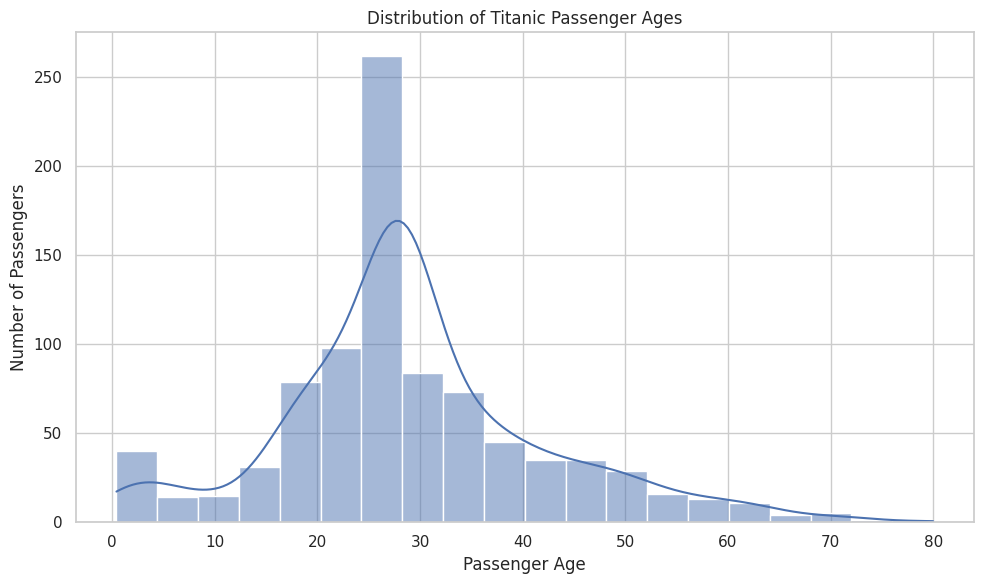

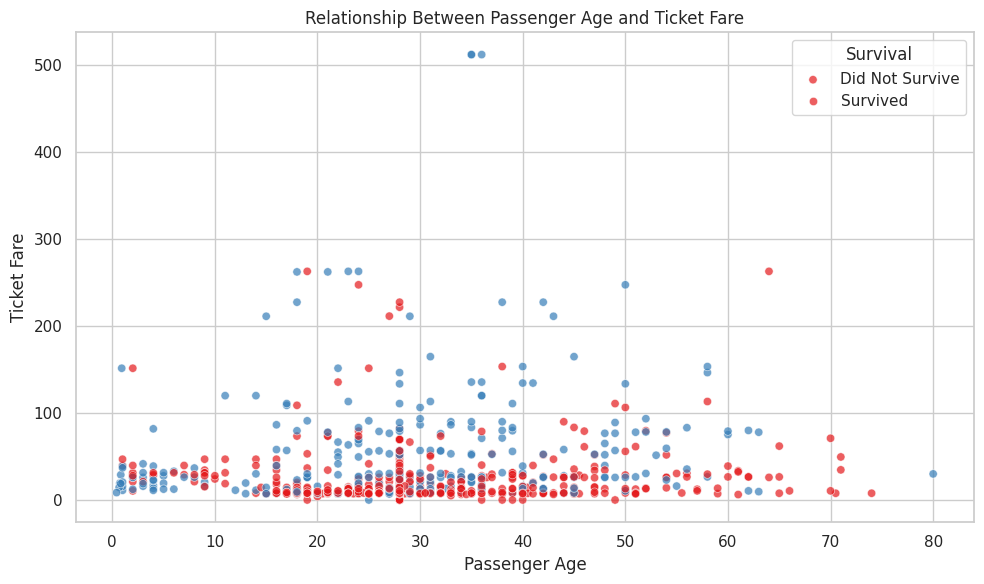


Correlation Between Age and Fare:
0.097

Average Passenger Age:
29.36

Median Passenger Age:
28.0

Average Ticket Fare:
32.2

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Rate:
38.38 %

Cleaned Dataset Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")


uploaded = files.upload()

df = pd.read_csv("train.csv")

print("Original Dataset")
print("Dataset Shape:", df.shape)
display(df.head())


print("\nDataset Information")
df.info()

print("\nStatistical Summary")
display(df.describe())



print("\nMissing Values Before Cleaning")
print(df.isnull().sum())

print("\nDuplicate Records Before Cleaning")
print(df.duplicated().sum())


cleaned_df = df.copy()


cleaned_df = cleaned_df.drop_duplicates()


cleaned_df["Age"] = cleaned_df["Age"].fillna(
    cleaned_df["Age"].median()
)

cleaned_df["Fare"] = cleaned_df["Fare"].fillna(
    cleaned_df["Fare"].median()
)

cleaned_df["Embarked"] = cleaned_df["Embarked"].fillna(
    cleaned_df["Embarked"].mode()[0]
)

cleaned_df = cleaned_df.drop(
    columns=["Cabin", "Name", "Ticket"],
    errors="ignore"
)


cleaned_df["Age"] = pd.to_numeric(
    cleaned_df["Age"], errors="coerce"
)

cleaned_df["Fare"] = pd.to_numeric(
    cleaned_df["Fare"], errors="coerce"
)


cleaned_df = cleaned_df.dropna(
    subset=["Age", "Fare"]
)

print("\nCleaned Dataset")
print("Dataset Shape:", cleaned_df.shape)
display(cleaned_df.head())

print("\nMissing Values After Cleaning")
print(cleaned_df.isnull().sum())

print("\nDuplicates After Cleaning")
print(cleaned_df.duplicated().sum())

print("\nCleaning Summary")
print("Original Records:", len(df))
print("Cleaned Records:", len(cleaned_df))
print("Records Removed:", len(df) - len(cleaned_df))

plt.figure(figsize=(10, 6))

sns.histplot(
    data=cleaned_df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Titanic Passenger Ages")
plt.xlabel("Passenger Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.savefig("titanic_age_histogram.png", dpi=300)
plt.show()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cleaned_df,
    x="Age",
    y="Fare",
    hue="Survived",
    alpha=0.7,
    palette="Set1"
)

plt.title("Relationship Between Passenger Age and Ticket Fare")
plt.xlabel("Passenger Age")
plt.ylabel("Ticket Fare")

plt.legend(
    title="Survival",
    labels=["Did Not Survive", "Survived"]
)

plt.tight_layout()
plt.savefig("titanic_age_fare_scatter.png", dpi=300)
plt.show()

correlation = cleaned_df["Age"].corr(
    cleaned_df["Fare"]
)

print("\nCorrelation Between Age and Fare:")
print(round(correlation, 3))

print("\nAverage Passenger Age:")
print(round(cleaned_df["Age"].mean(), 2))

print("\nMedian Passenger Age:")
print(round(cleaned_df["Age"].median(), 2))

print("\nAverage Ticket Fare:")
print(round(cleaned_df["Fare"].mean(), 2))

print("\nSurvival Count:")
print(cleaned_df["Survived"].value_counts())

print("\nSurvival Rate:")
print(round(cleaned_df["Survived"].mean() * 100, 2), "%")


cleaned_df.to_csv(
    "titanic_cleaned.csv",
    index=False
)

print("\nCleaned Dataset Saved Successfully!")


files.download("titanic_cleaned.csv")
files.download("titanic_age_histogram.png")
files.download("titanic_age_fare_scatter.png")
